# StreamBench: Real Local Qwen Evaluation

This notebook runs the official StreamBench HotpotQA distract task with local Qwen2.5-0.5B-Instruct and Qwen2.5-1.5B-Instruct. It compares Zero-shot, Fixed Few-shot, and Self-StreamICL using binary normalized exact-match feedback. Models run serially; the first is released before the second is loaded. MAM-StreamICL is not implemented.

## 1. Configuration

The official test parquet contains 1,500 rows. This executed run uses the first 96 rows to fit the six-condition CPU run on the available 16 GB Apple Silicon computer. The first four rows are a fixed support pool excluded from scoring; the remaining 92 rows are the common evaluation stream.

In [ ]:
from pathlib import Path
import gc, os, re, string, sys, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings("ignore")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
SEED = 42
np.random.seed(SEED)
ROOT = Path.cwd()
DATA_PATH = ROOT / "real_run/data/hotpotqa_test.parquet"
SMALL_PATH = ROOT / "real_run/models/qwen2.5-0.5b-instruct"
LARGE_PATH = ROOT / "real_run/models/qwen2.5-1.5b-instruct"
RESULTS_PATH = ROOT / "real_run/results_qwen_streambench.csv"
SUMMARY_PATH = ROOT / "real_run/summary_qwen_streambench.csv"
DATASET_ID, DATASET_CONFIG, DATASET_SPLIT = "appier-ai-research/StreamBench", "hotpotqa_distract", "test"
STREAM_ROWS, FIXED_FEWSHOT_K, RETRIEVAL_K = 96, 4, 4
MAX_NEW_TOKENS, CONTEXT_CHAR_LIMIT, PROGRESS_EVERY = 8, 3000, 8
print(f"Python: {sys.version.split()[0]}")
print(f"Dataset: {DATASET_ID}/{DATASET_CONFIG}/{DATASET_SPLIT}")
print(f"Official parquet: {DATA_PATH} ({DATA_PATH.stat().st_size / 1e6:.2f} MB)")
print(f"Fixed hyperparameters: seed={SEED}, prefix={STREAM_ROWS}, fixed_k={FIXED_FEWSHOT_K}, retrieval_k={RETRIEVAL_K}, max_new_tokens={MAX_NEW_TOKENS}")

Python: 3.12.2
Dataset: appier-ai-research/StreamBench/hotpotqa_distract/test
Official parquet: /Users/luran/Documents/ChatGPT/Frugal AI/real_run/data/hotpotqa_test.parquet (5.57 MB)
Fixed hyperparameters: seed=42, prefix=96, fixed_k=4, retrieval_k=4, max_new_tokens=8


## 2. Load the official stream

The official parquet is loaded locally. The four support examples are separated before scoring, and all conditions use the same remaining stream.

In [ ]:
full_stream = pd.read_parquet(DATA_PATH)
required = {"id", "question", "answer", "type", "level", "context"}
assert required.issubset(full_stream.columns), f"Missing columns: {required - set(full_stream.columns)}"
stream = full_stream.head(STREAM_ROWS).reset_index(drop=True).copy()
support_pool = stream.head(FIXED_FEWSHOT_K).copy()
eval_stream = stream.iloc[FIXED_FEWSHOT_K:].reset_index(drop=True).copy()
print(f"Official rows available: {len(full_stream):,}")
print(f"Executed prefix: {len(stream):,}; held-out support rows: {len(support_pool)}")
print(f"Scored rows per condition: {len(eval_stream):,}")
print("Task mix:\n" + eval_stream["type"].value_counts().to_string())
display(eval_stream[["id", "type", "level", "question", "answer"]].head(6))

Official rows available: 1,500
Executed prefix: 96; held-out support rows: 4
Scored rows per condition: 92
Task mix:
type
bridge        75
comparison    17
                      id       type level                                                                                                   question                           answer
5a8e3ea95542995a26add48d     bridge  hard                        The director of the romantic comedy "Big Stone Gap" is based in what New York city? Greenwich Village, New York City
5abd94525542992ac4f382d2     bridge  hard                            2014 S/S is the debut album of a South Korean boy group that was formed by who?                 YG Entertainment
5a85b2d95542997b5ce40028     bridge  hard Who was known by his stage name Aladin and helped organizations improve their performance as a consultant?                    Eenasul Fateh
5a87ab905542996e4f3088c1     bridge  hard                   The arena where the Lewiston Maineiacs played their home

## 3. Binary feedback and retrieval utilities

Correctness uses HotpotQA normalized exact match. Self-StreamICL stores only examples receiving feedback 1. A lexical Jaccard retriever avoids a second model; nested HotpotQA context is included in every prompt.

In [ ]:
TOKEN_RE = re.compile(r"\w+", flags=re.UNICODE)
ARTICLE_RE = re.compile(r"\b(a|an|the)\b", flags=re.IGNORECASE)
def normalize_answer(text):
    punctuation = set(string.punctuation)
    text = "".join(char for char in str(text).lower() if char not in punctuation)
    text = ARTICLE_RE.sub(" ", text)
    return " ".join(text.split())
def exact_match(prediction, gold):
    return int(normalize_answer(prediction) == normalize_answer(gold))
def token_set(text):
    return set(TOKEN_RE.findall(str(text).lower()))
def lexical_similarity(a, b):
    left, right = token_set(a), token_set(b)
    return len(left & right) / max(1, len(left | right))
def context_to_text(context, limit=CONTEXT_CHAR_LIMIT):
    if not isinstance(context, dict):
        return str(context)[:limit]
    lines = [f"{title}: {' '.join(map(str, para))}" for title, para in zip(context.get("title", []), context.get("sentences", []))]
    return "\n".join(lines)[:limit]
def retrieve(memory, question):
    ranked = [(lexical_similarity(question, x["question"]), x) for x in memory]
    ranked.sort(key=lambda pair: pair[0], reverse=True)
    return [(score, item) for score, item in ranked[:RETRIEVAL_K] if score > 0]
def answer_line(text):
    text = re.sub(r"^answer\s*:\s*", "", str(text).strip(), flags=re.IGNORECASE)
    return text.splitlines()[0].strip()
def format_examples(examples):
    return "\n".join(f"Example question: {x['question']}\nExample answer: {x['answer']}" for x in examples)
print("Utilities ready. First prompt context chars:", len(context_to_text(eval_stream.iloc[0]["context"])))

Utilities ready. First prompt context chars: 3000


## 4. Local Transformers model adapter

The adapter loads only from local folders. It uses MPS float16 when available and CPU float32 otherwise. Greedy generation is capped at eight tokens across conditions.

In [ ]:
class HFQwenAgent:
    def __init__(self, model_path):
        import torch
        from transformers import AutoModelForCausalLM, AutoTokenizer
        self.torch = torch
        self.path = Path(model_path)
        self.tokenizer = AutoTokenizer.from_pretrained(self.path, local_files_only=True)
        self.device = "mps" if torch.backends.mps.is_available() else "cpu"
        self.dtype = torch.float16 if self.device == "mps" else torch.float32
        self.model = AutoModelForCausalLM.from_pretrained(self.path, torch_dtype=self.dtype, local_files_only=True)
        self.model.to(self.device)
        self.model.eval()
        self.model.generation_config.do_sample = False
        self.model.generation_config.temperature = None
        self.model.generation_config.top_p = None
        self.model.generation_config.top_k = None
        self.parameter_count = sum(p.numel() for p in self.model.parameters())
    def generate(self, question, examples, context):
        demos = format_examples(examples)
        prompt = ("Answer using the context. Return only a short exact answer, without explanation.\n"
                  + (f"Demonstrations:\n{demos}\n" if demos else "")
                  + f"Context:\n{context_to_text(context)}\nQuestion: {question}\nAnswer:")
        rendered = self.tokenizer.apply_chat_template([{"role": "user", "content": prompt}], tokenize=False, add_generation_prompt=True)
        inputs = self.tokenizer(rendered, return_tensors="pt")
        inputs = {key: value.to(self.device) for key, value in inputs.items()}
        with self.torch.inference_mode():
            output = self.model.generate(**inputs, max_new_tokens=MAX_NEW_TOKENS, do_sample=False,
                                         pad_token_id=self.tokenizer.eos_token_id)
        generated = output[0, inputs["input_ids"].shape[1]:]
        return answer_line(self.tokenizer.decode(generated, skip_special_tokens=True))
print("Real Qwen adapter defined.")

Real Qwen adapter defined.


## 5. Serial streaming evaluation

Zero-shot has no examples, Fixed Few-shot uses the frozen four-row support pool, and Self-StreamICL retrieves previous correct predictions only. Logs preserve prediction, binary feedback, memory size, and retrieval similarity.

In [ ]:
def run_condition(agent, baseline, model_label, frame, fixed_examples):
    memory, rows = [], []
    started = time.time()
    for t, (_, item) in enumerate(frame.iterrows(), start=1):
        if baseline == "Zero-shot":
            examples, retrieved = [], []
        elif baseline == "Fixed Few-shot":
            examples, retrieved = fixed_examples, []
        else:
            retrieved = retrieve(memory, str(item.question))
            examples = [value for _, value in retrieved]
        prediction = agent.generate(str(item.question), examples, item.context)
        feedback = exact_match(prediction, item.answer)
        if baseline == "Self-StreamICL" and feedback:
            memory.append({"question": str(item.question), "answer": str(item.answer), "feedback": 1})
        rows.append({"t": t, "stream_row": t + FIXED_FEWSHOT_K, "model": model_label, "baseline": baseline,
                     "id": str(item.id), "type": str(item.type), "level": str(item.level),
                     "question": str(item.question), "gold": str(item.answer), "prediction": prediction,
                     "feedback": feedback, "memory_size": len(memory), "retrieved_k": len(retrieved),
                     "top_similarity": float(retrieved[0][0]) if retrieved else 0.0})
        if t == 1 or t % PROGRESS_EVERY == 0 or t == len(frame):
            acc = np.mean([row["feedback"] for row in rows])
            print(f"  {model_label} / {baseline}: {t:>3}/{len(frame)} | accuracy={acc:.3f} | memory={len(memory)} | elapsed={time.time()-started:.1f}s")
    out = pd.DataFrame(rows)
    out["cumulative_accuracy"] = out.feedback.expanding().mean()
    out["retrieval_quality"] = pd.cut(out.top_similarity, [-0.001, 0.05, 0.20, 1.0], labels=["none_or_weak", "medium", "strong"])
    return out

completed_logs = []
def checkpoint_results():
    if completed_logs:
        checkpoint = pd.concat(completed_logs, ignore_index=True)
        checkpoint["model_parameters"] = checkpoint.model.map({"Qwen2.5-0.5B": 494_032_768, "Qwen2.5-1.5B": 1_543_714_304})
        checkpoint.to_csv(RESULTS_PATH, index=False)
        print(f"Checkpoint saved: {len(checkpoint):,} predictions")

def run_model(model_label, model_path):
    print(f"\\n=== LOAD {model_label}: {model_path} ===")
    started = time.time()
    agent = HFQwenAgent(model_path)
    print(f"device={agent.device}; dtype={agent.dtype}; parameters={agent.parameter_count:,}; load_seconds={time.time()-started:.1f}")
    fixed = [{"question": str(row.question), "answer": str(row.answer), "feedback": 1} for _, row in support_pool.iterrows()]
    logs = []
    for baseline in ["Zero-shot", "Fixed Few-shot", "Self-StreamICL"]:
        print(f"\\n--- START {baseline} ---")
        condition_log = run_condition(agent, baseline, model_label, eval_stream, fixed)
        logs.append(condition_log)
        completed_logs.append(condition_log)
        checkpoint_results()
    result = pd.concat(logs, ignore_index=True)
    print(f"=== RELEASE {model_label} ===")
    del agent
    gc.collect()
    try:
        import torch
        if torch.backends.mps.is_available():
            torch.mps.empty_cache()
    except Exception:
        pass
    return result

run_started = time.time()
small_results = run_model("Qwen2.5-0.5B", SMALL_PATH)
print("Small model released before loading large model.")
large_results = run_model("Qwen2.5-1.5B", LARGE_PATH)
results = pd.concat([small_results, large_results], ignore_index=True)
results["model_parameters"] = results.model.map({"Qwen2.5-0.5B": 494_032_768, "Qwen2.5-1.5B": 1_543_714_304})
results.to_csv(RESULTS_PATH, index=False)
print(f"Completed {len(results):,} real Qwen predictions in {time.time()-run_started:.1f}s.")
print("Raw predictions:", RESULTS_PATH)
display(results.head(8))

\n=== LOAD Qwen2.5-0.5B: /Users/luran/Documents/ChatGPT/Frugal AI/real_run/models/qwen2.5-0.5b-instruct ===
device=cpu; dtype=torch.float32; parameters=494,032,768; load_seconds=2.8
\n--- START Zero-shot ---
  Qwen2.5-0.5B / Zero-shot:   1/92 | accuracy=0.000 | memory=0 | elapsed=2.6s
  Qwen2.5-0.5B / Zero-shot:   8/92 | accuracy=0.000 | memory=0 | elapsed=20.6s
  Qwen2.5-0.5B / Zero-shot:  16/92 | accuracy=0.000 | memory=0 | elapsed=41.4s
  Qwen2.5-0.5B / Zero-shot:  24/92 | accuracy=0.042 | memory=0 | elapsed=61.2s
  Qwen2.5-0.5B / Zero-shot:  32/92 | accuracy=0.062 | memory=0 | elapsed=82.0s
  Qwen2.5-0.5B / Zero-shot:  40/92 | accuracy=0.050 | memory=0 | elapsed=101.5s
  Qwen2.5-0.5B / Zero-shot:  48/92 | accuracy=0.062 | memory=0 | elapsed=122.2s
  Qwen2.5-0.5B / Zero-shot:  56/92 | accuracy=0.054 | memory=0 | elapsed=144.1s
  Qwen2.5-0.5B / Zero-shot:  64/92 | accuracy=0.047 | memory=0 | elapsed=164.9s
  Qwen2.5-0.5B / Zero-shot:  72/92 | accuracy=0.069 | memory=0 | elapsed=184.2

## 6. Summary metrics and paired gains

The summary compares exact-match accuracy, cumulative endpoint accuracy, retrieval coverage, final memory, and mean similarity. Gains are paired within each model.

In [ ]:
summary = results.groupby(["model", "baseline"], as_index=False).agg(
    accuracy=("feedback", "mean"), final_cumulative_accuracy=("cumulative_accuracy", "last"),
    mean_retrieved_k=("retrieved_k", "mean"), final_memory=("memory_size", "last"),
    mean_top_similarity=("top_similarity", "mean"), total=("feedback", "size"))
summary["accuracy_pct"] = 100 * summary.accuracy
summary.to_csv(SUMMARY_PATH, index=False)
print("Summary CSV:", SUMMARY_PATH)
display(summary.round(4))
pivot = summary.pivot(index="model", columns="baseline", values="accuracy")
gains = pd.DataFrame({
    "Self-StreamICL minus Zero-shot (pp)": 100 * (pivot["Self-StreamICL"] - pivot["Zero-shot"]),
    "Self-StreamICL minus Fixed Few-shot (pp)": 100 * (pivot["Self-StreamICL"] - pivot["Fixed Few-shot"]),
}).reset_index()
print("Paired gains, percentage points:")
display(gains.round(2))

Summary CSV: /Users/luran/Documents/ChatGPT/Frugal AI/real_run/summary_qwen_streambench.csv
       model       baseline  accuracy  final_cumulative_accuracy  mean_retrieved_k  final_memory  mean_top_similarity  total  accuracy_pct
Qwen2.5-0.5B Fixed Few-shot    0.0978                     0.0978            0.0000             0               0.0000     92        9.7826
Qwen2.5-0.5B Self-StreamICL    0.1304                     0.1304            2.3370            12               0.0876     92       13.0435
Qwen2.5-0.5B      Zero-shot    0.0978                     0.0978            0.0000             0               0.0000     92        9.7826
Qwen2.5-1.5B Fixed Few-shot    0.3043                     0.3043            0.0000             0               0.0000     92       30.4348
Qwen2.5-1.5B Self-StreamICL    0.2826                     0.2826            3.5217            26               0.1329     92       28.2609
Qwen2.5-1.5B      Zero-shot    0.2500                     0.2500          

## 7. Visual analysis

Plots show cumulative accuracy over time, Self-StreamICL memory growth, model-size comparisons, and correctness by lexical retrieval quality.

Memory/performance correlation:
       model  corr(memory_size, feedback)
Qwen2.5-0.5B                       0.2188
Qwen2.5-1.5B                       0.0290


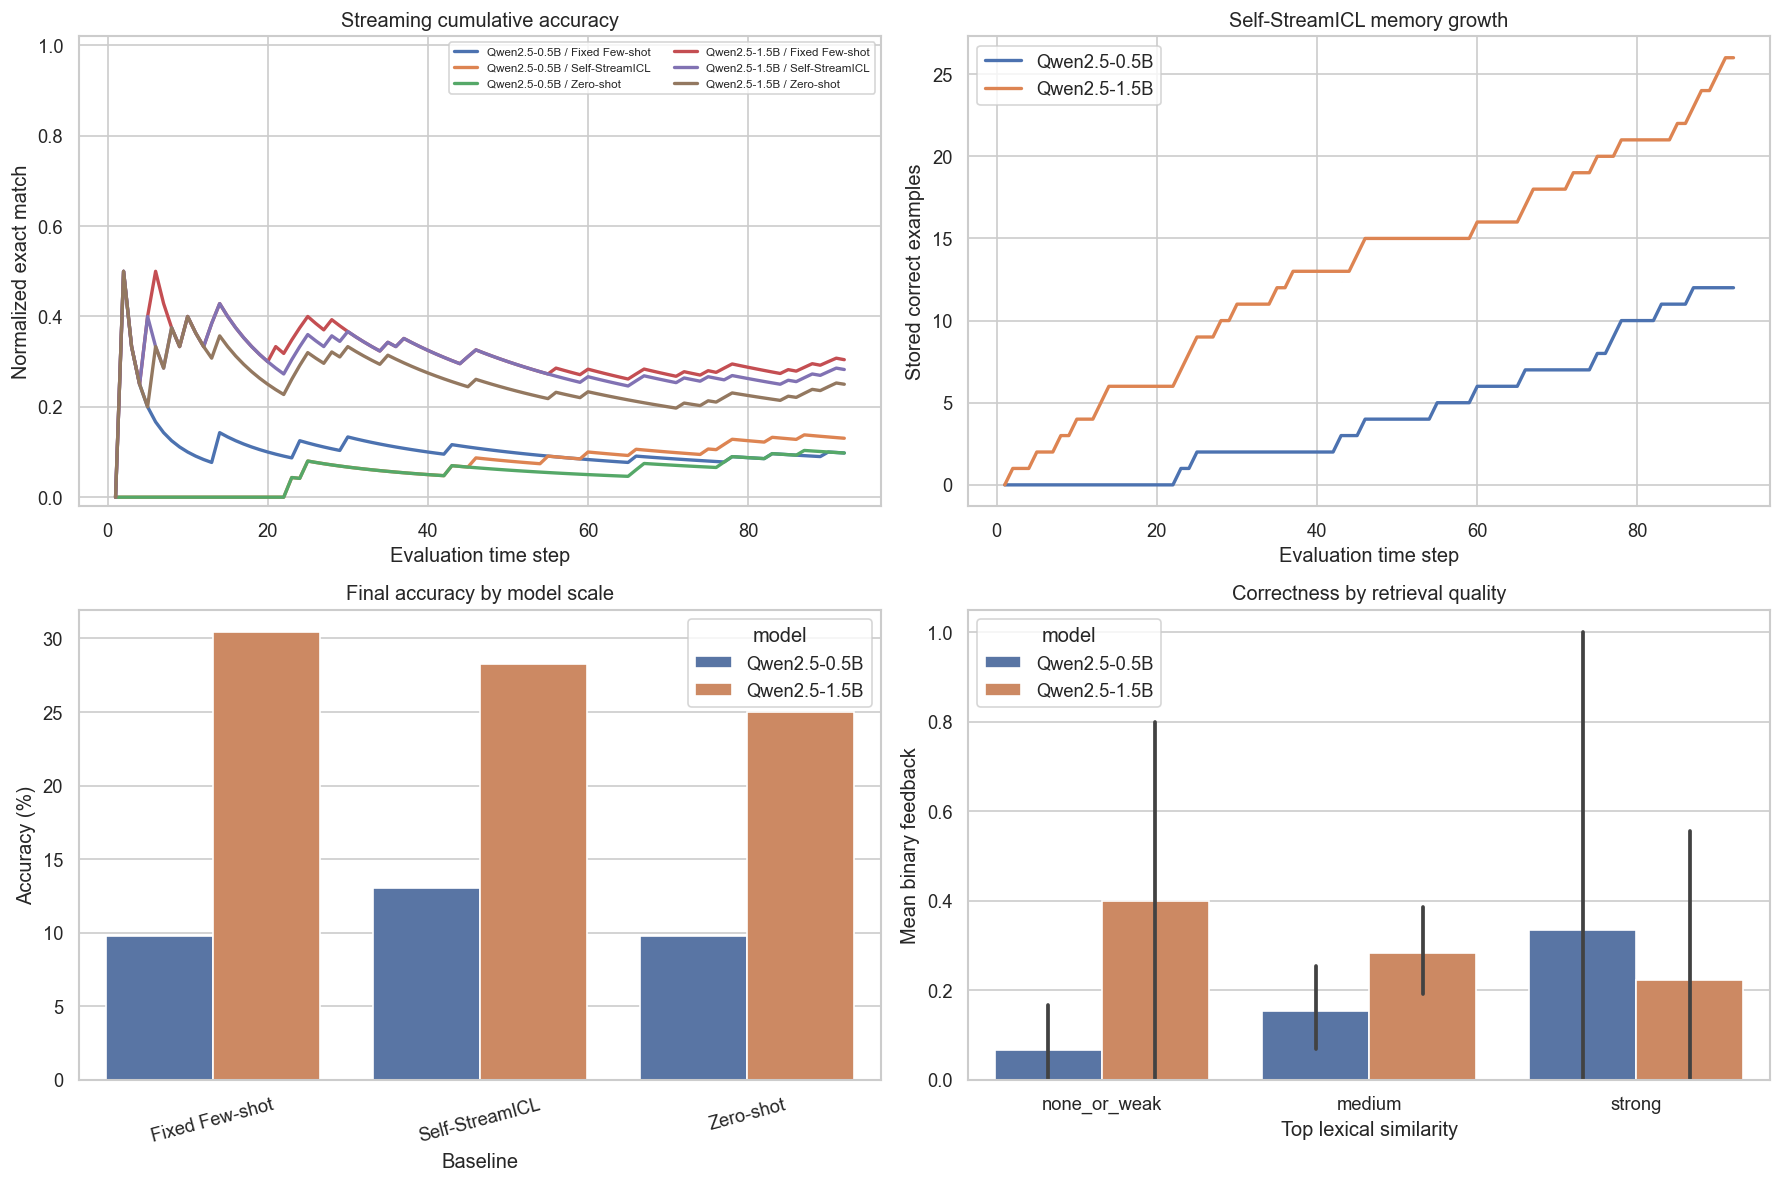

In [ ]:
sns.set_theme(style="whitegrid", context="notebook")
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for (model, baseline), group in results.groupby(["model", "baseline"]):
    axes[0, 0].plot(group.t, group.cumulative_accuracy, linewidth=2, label=f"{model} / {baseline}")
axes[0, 0].set(title="Streaming cumulative accuracy", xlabel="Evaluation time step", ylabel="Normalized exact match", ylim=(-0.02, 1.02))
axes[0, 0].legend(fontsize=7, ncol=2)
for model, group in results[results.baseline == "Self-StreamICL"].groupby("model"):
    axes[0, 1].plot(group.t, group.memory_size, linewidth=2, label=model)
axes[0, 1].set(title="Self-StreamICL memory growth", xlabel="Evaluation time step", ylabel="Stored correct examples")
axes[0, 1].legend()
sns.barplot(data=summary, x="baseline", y="accuracy_pct", hue="model", ax=axes[1, 0])
axes[1, 0].set(title="Final accuracy by model scale", xlabel="Baseline", ylabel="Accuracy (%)")
axes[1, 0].tick_params(axis="x", rotation=15)
self_results = results[results.baseline == "Self-StreamICL"].copy()
sns.barplot(data=self_results, x="retrieval_quality", y="feedback", hue="model", ax=axes[1, 1])
axes[1, 1].set(title="Correctness by retrieval quality", xlabel="Top lexical similarity", ylabel="Mean binary feedback")
plt.tight_layout()
plt.show()
memory_corr = self_results.groupby("model").apply(lambda group: group.memory_size.corr(group.feedback)).rename("corr(memory_size, feedback)").reset_index()
print("Memory/performance correlation:")
display(memory_corr.round(4))

## 8. Error analysis and feedback audit

This table contains raw Qwen generations for representative incorrect answers. The audit summarizes binary feedback and memory is updated only after a correct answer.

In [ ]:
error_cases = results[results.feedback == 0].sort_values(["model", "baseline", "t"])[
    ["model", "baseline", "t", "type", "question", "gold", "prediction", "retrieved_k", "top_similarity"]
].head(18)
display(error_cases)
feedback_audit = results.groupby(["model", "baseline"], as_index=False).agg(correct=("feedback", "sum"), total=("feedback", "size"))
feedback_audit["error_rate"] = 1 - feedback_audit.correct / feedback_audit.total
display(feedback_audit)
print("Self-StreamICL memory updates only after normalized exact match returns feedback=1.")

       model       baseline  t       type                                                                                                                                                          question                             gold                                       prediction  retrieved_k  top_similarity
Qwen2.5-0.5B Fixed Few-shot  1     bridge                                                                               The director of the romantic comedy "Big Stone Gap" is based in what New York city? Greenwich Village, New York City                                              yes            0             0.0
Qwen2.5-0.5B Fixed Few-shot  3     bridge                                                        Who was known by his stage name Aladin and helped organizations improve their performance as a consultant?                    Eenasul Fateh                                Chief of Protocol            0             0.0
Qwen2.5-0.5B Fixed Few-shot  4     bridge              

## 9. Interpretation and limitations

* Overall performance compares three matched baselines.
* Cumulative curves show accuracy evolution in the observed stream, without a synthetic curriculum.
* Memory growth and its correlation with correctness are diagnostic, not causal.
* Paired gains compare Self-StreamICL with both controls for each model size.
* A larger backbone may start higher and have less headroom for retrieval adaptation.
* Lexical similarity does not guarantee semantic relevance; wrong-entity examples may have high overlap.
* PyTorch reported MPS unavailable, so this run uses CPU float32. Cloud GPU results are faster and can differ due to model scale, precision, quantization, prompts, decoding, context limits, and retriever quality.
* This saved run evaluates a 92-example scored prefix of the official 1,500-row test split. Four support rows are withheld from scoring but come from this same parquet because the separate official train parquet was unavailable.